# India local business website gap 2026 — EDA

Aggregated counts of active Google Maps listings in 19 Indian cities, and the share of them that list a website.
Source: Mantis index snapshot (Google Places API), scanned 31 Aug 2026. Only aggregates are published, no per-business rows.
Report: https://mantisai.in/resources/india-local-business-website-gap-2026

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

cells = pd.read_csv("india_city_category_website_gap_2026.csv")
cities = pd.read_csv("india_city_website_gap_2026.csv")
print(cells.shape, cities.shape)
cells.head()

(1083, 6) (19, 5)


,city,category,listings_count,share_with_website,share_without_website,method_date
0,Ahmedabad,Service,713,0.7097,0.2903,2026-08-31
1,Ahmedabad,General Contractor,266,0.7707,0.2293,2026-08-31
2,Ahmedabad,Consultant,242,0.8182,0.1818,2026-08-31
3,Ahmedabad,Uncategorised,241,0.7469,0.2531,2026-08-31
4,Ahmedabad,Educational Institution,207,0.5024,0.4976,2026-08-31


## 1. Sample size and overall gap

In [2]:
total = cities.listings_count.sum()
without = (cities.listings_count * cities.share_without_website).sum()
print(f"listings checked: {total:,}")
print(f"share with no website (pooled): {without / total:.1%}")
cities.describe()

listings checked: 96,287
share with no website (pooled): 37.5%


,listings_count,share_with_website,share_without_website
count,19.000000,19.000000,19.000000
mean,5067.736842,0.604605,0.395395
std,903.412410,0.132007,0.132007
min,1739.000000,0.203600,0.253000
25%,4997.500000,0.566900,0.314250
50%,5255.000000,0.637100,0.362900
75%,5585.000000,0.685750,0.433100
max,5744.000000,0.747000,0.796400


## 2. Cities ranked by share without a website

,city,listings_count,share_with_website,share_without_website,method_date
0,Morena,1739,0.2036,0.7964,2026-08-31
1,Kota,4140,0.3778,0.6222,2026-08-31
2,Faridabad,4889,0.5093,0.4907,2026-08-31
3,Surat,5213,0.5298,0.4702,2026-08-31
4,Chandigarh,4570,0.5613,0.4387,2026-08-31
5,Indore,4975,0.5725,0.4275,2026-08-31
6,Lucknow,5198,0.6029,0.3971,2026-08-31
7,Coimbatore,5224,0.6139,0.3861,2026-08-31
8,Jaipur,5393,0.6151,0.3849,2026-08-31
9,Ahmedabad,5572,0.6371,0.3629,2026-08-31


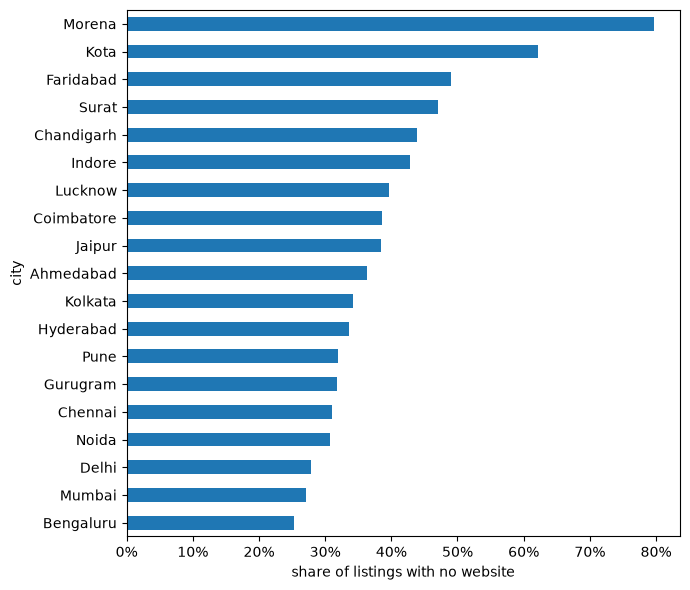

In [3]:
c = cities.sort_values("share_without_website")
ax = c.plot.barh(x="city", y="share_without_website", legend=False, figsize=(7, 6))
ax.set_xlabel("share of listings with no website")
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
plt.tight_layout()
cities.sort_values("share_without_website", ascending=False)

## 3. Categories: pooled across cities (categories with 300+ listings)

In [4]:
cells["without_n"] = cells.listings_count * cells.share_without_website
cat = cells.groupby("category").agg(listings=("listings_count", "sum"), without=("without_n", "sum"), cities=("city", "nunique"))
cat["share_without_website"] = cat.without / cat.listings
cat = cat[cat.listings >= 300].sort_values("share_without_website", ascending=False)
cat.round(3).head(20)

,listings,without,cities,share_without_website
category,,,,
Guest House,370,286.995,7,0.776
Barber Shop,636,469.003,16,0.737
Hardware Store,1037,759.997,19,0.733
Farm,569,414.003,15,0.728
Tailor,840,577.996,18,0.688
Plumber,834,573.012,16,0.687
Swimming Pool,355,239.003,9,0.673
Electrician,895,594.986,17,0.665
Locksmith,504,307.002,9,0.609


In [5]:
cat.round(3).tail(10)

,listings,without,cities,share_without_website
category,,,,
Dentist,428,78.999,11,0.185
Spa,898,164.999,18,0.184
Dental Clinic,1339,241.008,18,0.180
Car Rental,362,64.995,10,0.180
Doctor,1070,192.000,18,0.179
Car Dealer,1049,186.998,18,0.178
Travel Agency,999,148.006,18,0.148
Jewelry Store,1102,159.994,19,0.145
Preschool,920,132.990,17,0.145


## 4. Same category, different city: how much does the gap vary?

In [6]:
wide = cells[cells.category.isin(cat.head(12).index)].pivot_table(
    index="category", columns="city", values="share_without_website")
spread = (wide.max(axis=1) - wide.min(axis=1)).sort_values(ascending=False)
spread.round(3)

category
Bicycle Store           0.666
Locksmith               0.523
Car Wash                0.480
Swimming Pool           0.457
Tailor                  0.438
Barber Shop             0.433
Plumber                 0.420
Hardware Store          0.406
Guest House             0.377
Sporting Goods Store    0.355
Farm                    0.325
Electrician             0.281
dtype: float64

## Notes and limits
- This is a sample of the Mantis index, not a census. Cities and categories were scanned with search phrases, so the mix reflects what we scanned.
- A listing counts as "with website" if its website field holds anything, including a social page or a dead domain. The no-website share is therefore conservative.
- Cells with fewer than 30 listings are suppressed. Cities with fewer than 400 listings are excluded.
- The live report reads a later and larger index, so its figures differ slightly from this snapshot.